## SUPPORT VECTOR MACHINE

Pharmaceutical companies need to understand how
different patient characteristics influence drug
response.

The objective of this project is to develop a
machine learning classification model that predicts
whether a patient will respond positively to a drug.

**Target Variable:**
- 0 = No Response
- 1 = Positive Response**

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Data Loading and Understanding

The dataset contains 500 records and 6 columns.

It includes five independent variables and one
dependent variable (Drug Response).

The objective is to predict whether a patient
responds positively to a drug based on the
available patient-related features.

In [2]:
df= pd.read_csv("d:\\project\\10. SVM\\Pharma_Industry.csv")

In [3]:
df

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1
...,...,...,...,...,...,...
495,-1.553759,0.506938,0.817890,-0.661245,-1.345393,0
496,0.551476,1.714321,0.340589,1.712558,-0.496315,1
497,-1.072743,-0.221137,0.239247,1.112924,-0.285838,1
498,1.661259,0.245759,-0.457096,0.633355,0.657413,0


## 2. Exploratory Data Analysis (EDA)

The purpose of EDA is to understand the dataset,
identify patterns, examine distributions and
check data quality.

In [4]:
df.isnull().sum()

Drug Dosage (mg)                  0
Systolic Blood Pressure (mmHg)    0
Heart Rate (BPM)                  0
Liver Toxicity Index (U/L)        0
Blood Glucose Level (mg/dL)       0
Drug Response                     0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.shape

(500, 6)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB


In [8]:
df.columns

Index(['Drug Dosage (mg)', 'Systolic Blood Pressure (mmHg)',
       'Heart Rate (BPM)', 'Liver Toxicity Index (U/L)',
       'Blood Glucose Level (mg/dL)', 'Drug Response'],
      dtype='str')

In [9]:
correlation = df.corr(numeric_only=True)

print(correlation)

                                Drug Dosage (mg)  \
Drug Dosage (mg)                        1.000000   
Systolic Blood Pressure (mmHg)          0.090618   
Heart Rate (BPM)                        0.040571   
Liver Toxicity Index (U/L)              0.128127   
Blood Glucose Level (mg/dL)             0.012434   
Drug Response                           0.043457   

                                Systolic Blood Pressure (mmHg)  \
Drug Dosage (mg)                                      0.090618   
Systolic Blood Pressure (mmHg)                        1.000000   
Heart Rate (BPM)                                     -0.039195   
Liver Toxicity Index (U/L)                            0.283672   
Blood Glucose Level (mg/dL)                           0.037228   
Drug Response                                         0.305226   

                                Heart Rate (BPM)  Liver Toxicity Index (U/L)  \
Drug Dosage (mg)                        0.040571                    0.128127   
Systolic Blo

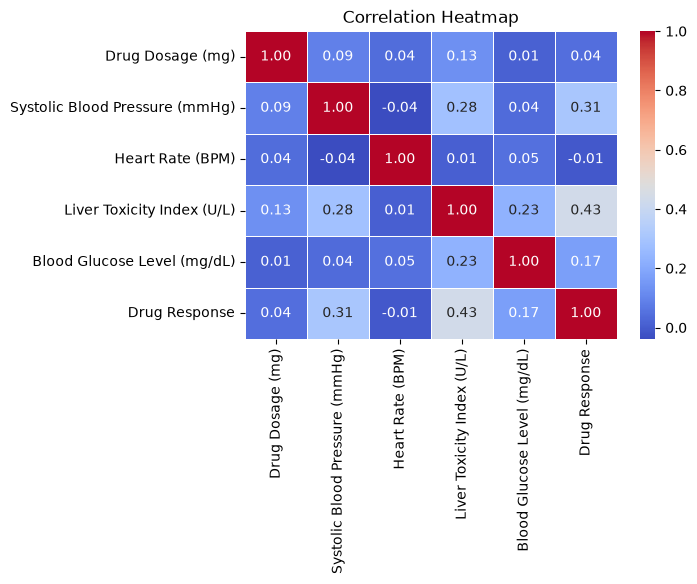

In [10]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

### Correlation Analysis

The correlation heatmap helps identify the
relationships between numerical features.

Liver Toxicity Index shows the strongest positive
correlation with Drug Response (approximately 0.43).

However, correlation alone does not establish
causation or determine the predictive importance
of a feature.

### Outlier Analysis

Box plots were used to identify potential outliers
in the independent variables.

Outliers were visually examined. Since SVM is
sensitive to feature distributions, their impact
should be considered before model training.

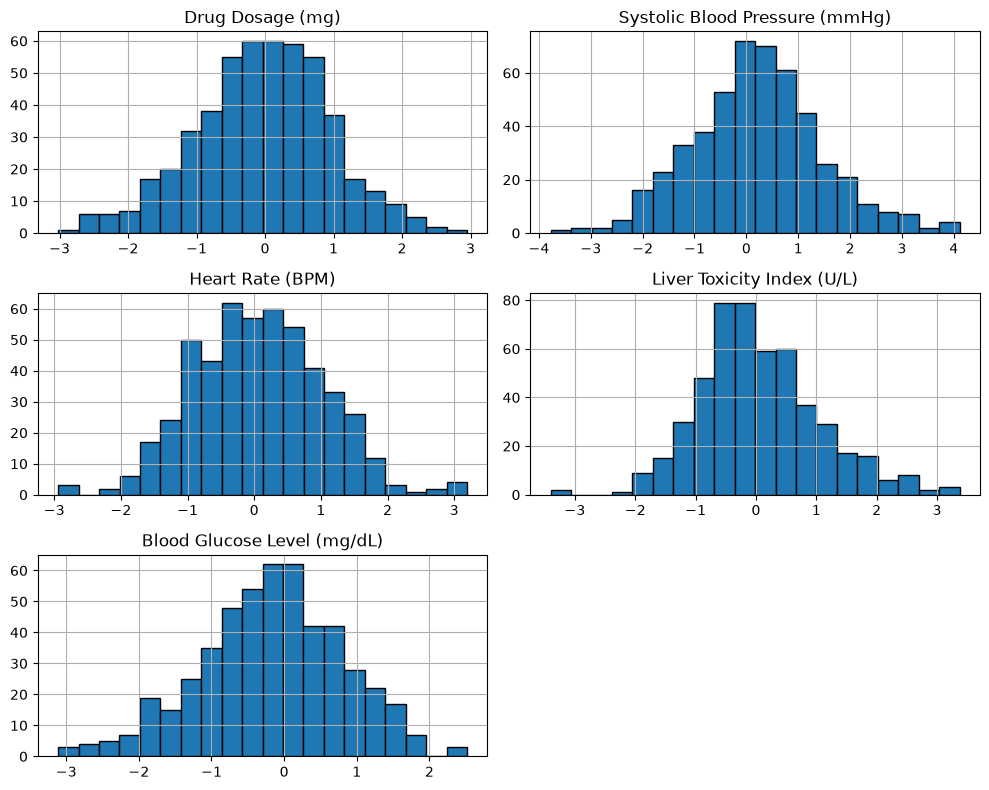

In [11]:

num_col=df.drop(columns=["Drug Response"])
num_col.hist(figsize=(10, 8), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

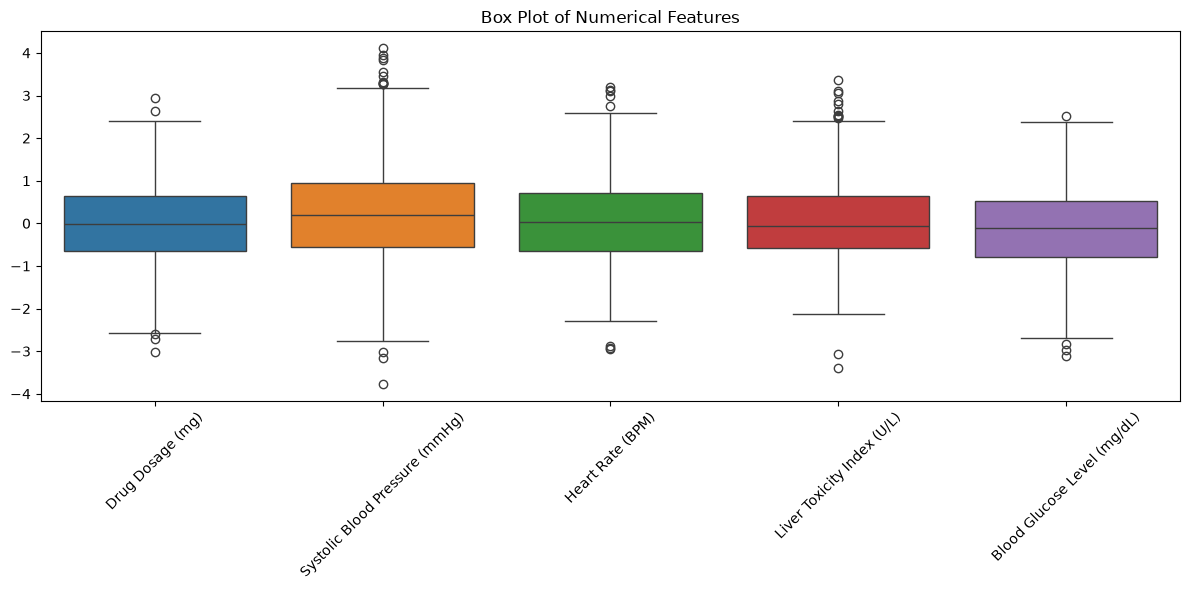

In [12]:

# Create box plots for numerical features
plt.figure(figsize=(12,6))

sns.boxplot(data=num_col)
plt.title("Box Plot of Numerical Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
X = df.drop('Drug Response', axis=1)

y = df['Drug Response']

print(X.shape, y.shape)

(500, 5) (500,)


In [14]:
print("Target variable distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print(y.value_counts(normalize=True) * 100)

Target variable distribution:
Drug Response
1    260
0    240
Name: count, dtype: int64

Target percentage:
Drug Response
1    52.0
0    48.0
Name: proportion, dtype: float64


### Target Variable Distribution

The dataset contains 500 observations.

48% of patients belong to the No Response
class, while 52% belong to the Positive Response
class.

The target variable is relatively balanced,
so there is no major class imbalance.

In [15]:
X.describe().loc[["mean", "std"]].T

,mean,std
Drug Dosage (mg),-0.037761,0.979891
Systolic Blood Pressure (mmHg),0.214957,1.247567
Heart Rate (BPM),0.062871,0.971978
Liver Toxicity Index (U/L),0.054398,0.986001
Blood Glucose Level (mg/dL),-0.171863,0.983765


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training and testing data shapes:")
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

Training and testing data shapes:
(400, 5) (100, 5) (400,) (100,)


In [17]:
# Create a basic SVM classifier

svm_model = SVC()

# Train the model
svm_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [18]:
y_pred = svm_model.predict(X_test)

print("Predicted values:")
print(y_pred)





Predicted values:
[1 1 1 0 0 1 1 0 1 1 1 0 0 1 1 1 0 0 0 0 0 0 1 1 0 1 0 0 1 1 1 1 1 0 0 1 1
 0 0 1 1 0 0 1 0 0 1 0 0 1 0 0 0 1 0 0 0 1 1 1 0 0 0 0 1 0 0 1 1 1 1 1 1 0
 1 1 1 1 0 1 0 1 0 1 1 1 0 1 1 0 0 1 0 1 1 1 1 1 1 1]


## 3. Model Evaluation

The trained SVM model is evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

In [19]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

evaluation= pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

evaluation["Score"] = (evaluation["Score"] * 100).round(2)

evaluation

,Metric,Score
0,Accuracy,78.00
1,Precision,76.79
2,Recall,82.69
3,F1-score,79.63


In [20]:
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-score : {f1 * 100:.2f}%")

Accuracy : 78.00%
Precision: 76.79%
Recall   : 82.69%
F1-score : 79.63%


In [21]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.73      0.76        48
           1       0.77      0.83      0.80        52

    accuracy                           0.78       100
   macro avg       0.78      0.78      0.78       100
weighted avg       0.78      0.78      0.78       100



In [22]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[35, 13],
       [ 9, 43]])

### Model Evaluation Interpretation

The model achieved 78% accuracy on the test dataset.

It correctly classified 35 patients with no drug
response and 43 patients with a positive drug response.

However, 13 negative responses were incorrectly
classified as positive, and 9 positive responses
were incorrectly classified as negative.

The recall score of 82.69% indicates that the model
identified approximately 83% of actual positive
responses.

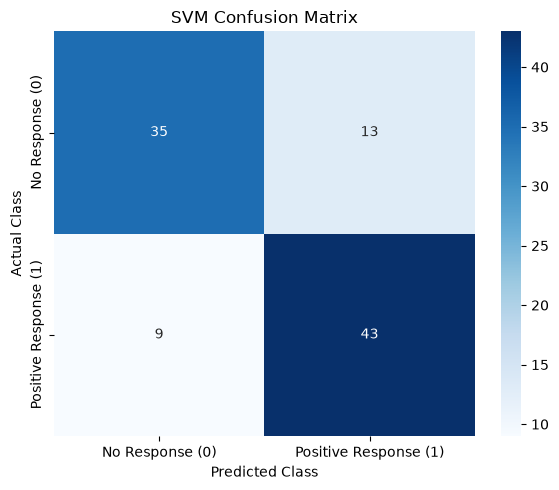

In [23]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
           xticklabels=['No Response (0)','Positive Response (1)'],
           yticklabels=['No Response (0)','Positive Response (1)'])

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


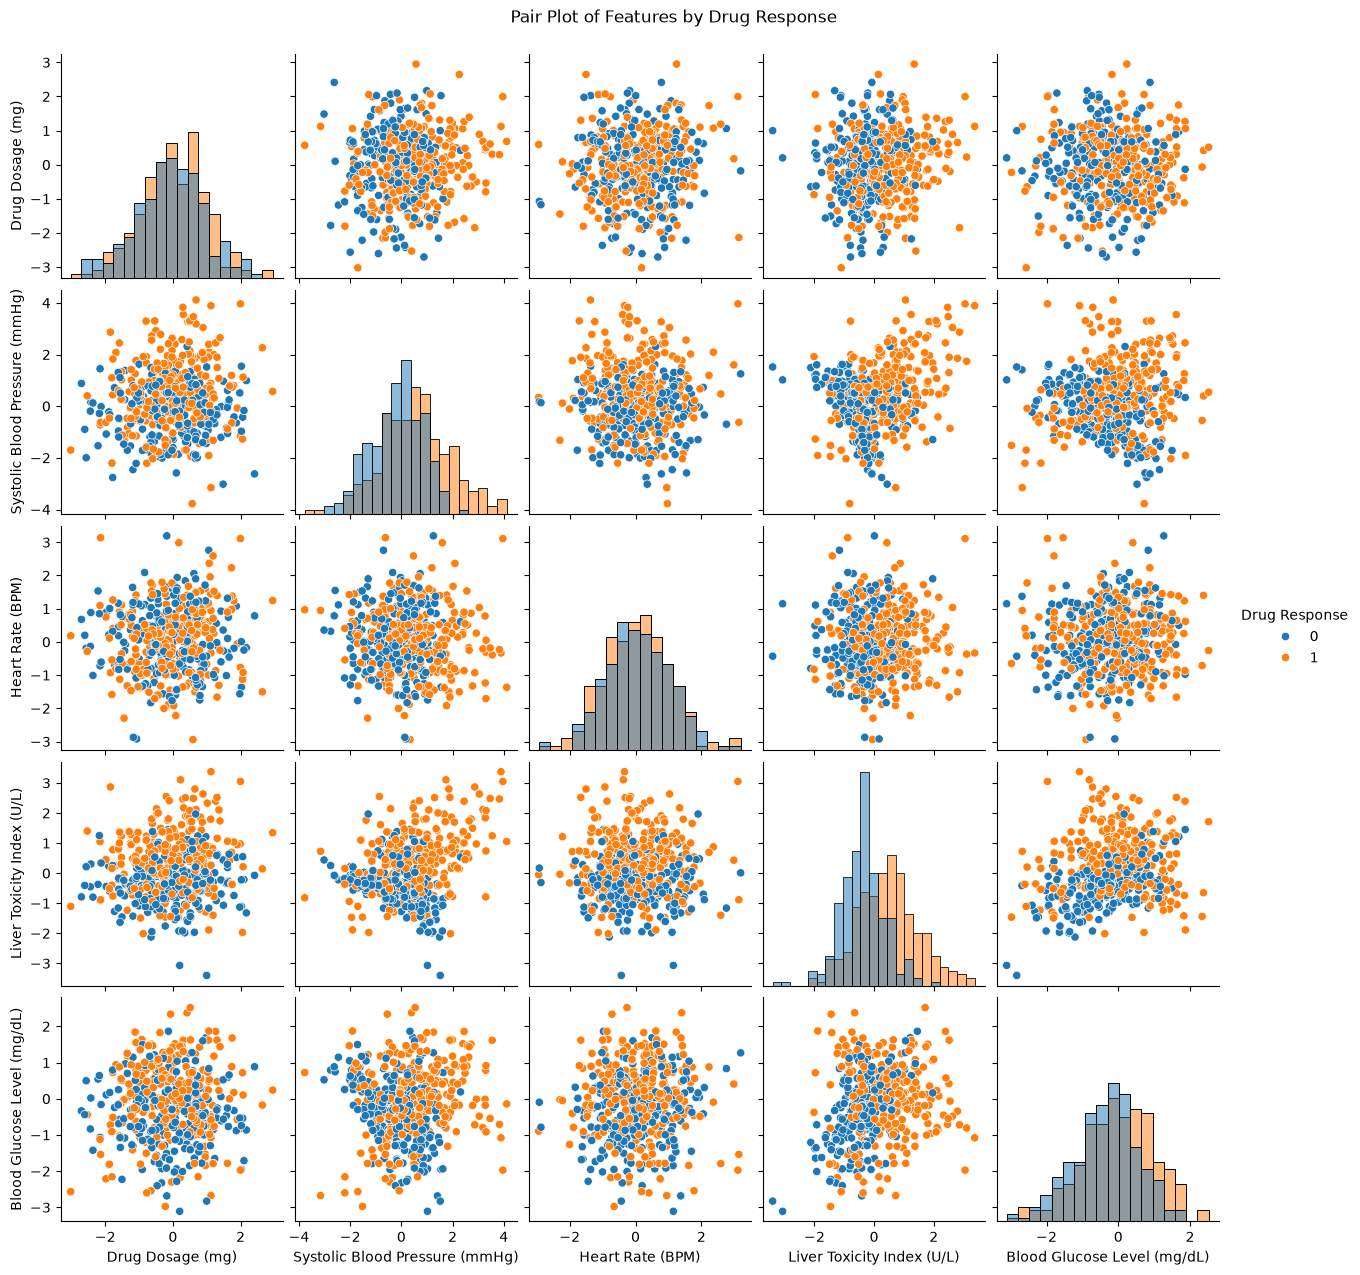

In [24]:
# Pair plot to visualize relationships between numerical features
sns.pairplot(df,hue="Drug Response",diag_kind="hist")
plt.suptitle("Pair Plot of Features by Drug Response", y=1.02)
plt.show()

### Pair Plot Analysis

The pair plot helps visualize the distribution
of individual features and relationships between
pairs of features across the two drug response classes.

It provides an initial understanding of whether
the classes show visible separation or overlap.

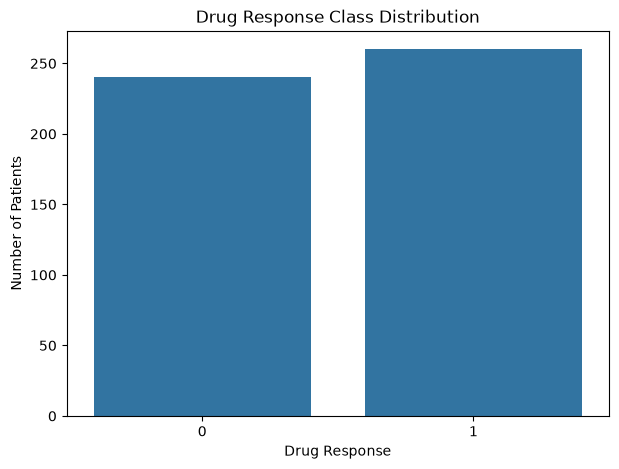

In [25]:
class_count = df["Drug Response"].value_counts().sort_index()

plt.figure(figsize=(7,5))

sns.countplot(data=df,x="Drug Response")
plt.title("Drug Response Class Distribution")
plt.xlabel("Drug Response")
plt.ylabel("Number of Patients")
plt.show()

In [26]:
# Define parameter combinations

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__kernel": ["linear", "poly", "rbf"]
}

# Grid Search with Cross Validation

grid_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC())
    ]),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svm', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svm__C': [0.1, 1, ...], 'svm__kernel': ['linear', 'poly', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of infor

In [27]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'svm__C': 10, 'svm__kernel': 'rbf'}
Best CV F1 Score: 0.7566117454889295


In [28]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)

print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.76      0.71      0.73        48
           1       0.75      0.79      0.77        52

    accuracy                           0.75       100
   macro avg       0.75      0.75      0.75       100
weighted avg       0.75      0.75      0.75       100



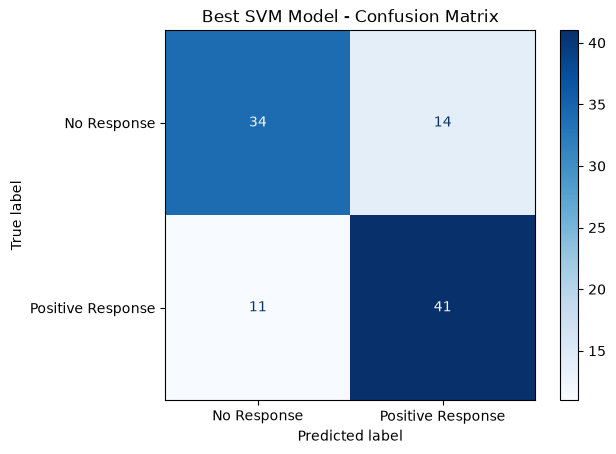

In [29]:
ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["No Response", "Positive Response"],
    cmap="Blues"
)

plt.title("Best SVM Model - Confusion Matrix")
plt.show()

In [30]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'svm__C': 10, 'svm__kernel': 'rbf'}
Best CV F1 Score: 0.7566117454889295


In [31]:
results = pd.DataFrame(grid_search.cv_results_)

comparison = results[[
    "param_svm__C",
    "param_svm__kernel",
    "mean_test_score",
    "std_test_score"
]]

comparison = comparison.sort_values(
    by="mean_test_score",
    ascending=False
)

comparison

,param_svm__C,param_svm__kernel,mean_test_score,std_test_score
8,10.0,rbf,0.756612,0.044706
5,1.0,rbf,0.754720,0.068459
11,100.0,rbf,0.746433,0.041942
2,0.1,rbf,0.727822,0.032830
9,100.0,linear,0.708769,0.048776
6,10.0,linear,0.708769,0.048776
7,10.0,poly,0.708434,0.066872
3,1.0,linear,0.705437,0.043859
0,0.1,linear,0.698727,0.041140
4,1.0,poly,0.693945,0.062767


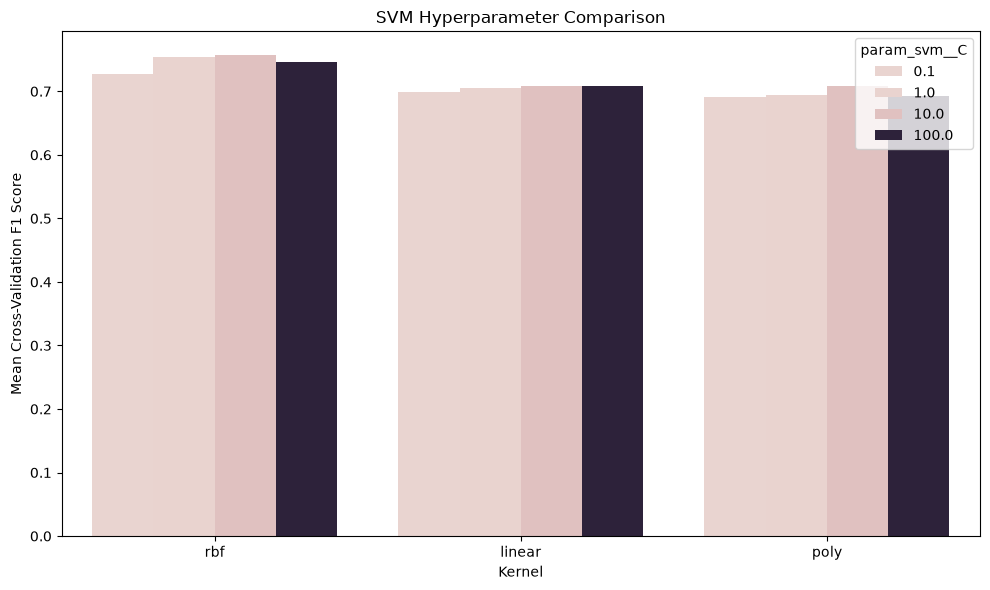

In [32]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison,
    x="param_svm__kernel",
    y="mean_test_score",
    hue="param_svm__C"
)

plt.title("SVM Hyperparameter Comparison")
plt.xlabel("Kernel")
plt.ylabel("Mean Cross-Validation F1 Score")
plt.tight_layout()
plt.show()

In [33]:
results = pd.DataFrame(grid_search.cv_results_)

comparison = results[[
    "param_svm__C",
    "param_svm__kernel",
    "mean_test_score",
    "std_test_score"
]]

comparison = comparison.sort_values(
    by="mean_test_score",
    ascending=False
)

comparison

,param_svm__C,param_svm__kernel,mean_test_score,std_test_score
8,10.0,rbf,0.756612,0.044706
5,1.0,rbf,0.754720,0.068459
11,100.0,rbf,0.746433,0.041942
2,0.1,rbf,0.727822,0.032830
9,100.0,linear,0.708769,0.048776
6,10.0,linear,0.708769,0.048776
7,10.0,poly,0.708434,0.066872
3,1.0,linear,0.705437,0.043859
0,0.1,linear,0.698727,0.041140
4,1.0,poly,0.693945,0.062767


In [34]:
y_scores = best_model.decision_function(X_test)

roc_auc = roc_auc_score(y_test, y_scores)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.8069


In [35]:
print("Best SVM Configuration:")
print(grid_search.best_params_)

print("\nTest Accuracy:",
      round(accuracy_score(y_test, y_pred_best) * 100, 2), "%")

print("Test Precision:",
      round(precision_score(y_test, y_pred_best) * 100, 2), "%")

print("Test Recall:",
      round(recall_score(y_test, y_pred_best) * 100, 2), "%")

print("Test F1 Score:",
      round(f1_score(y_test, y_pred_best) * 100, 2), "%")

Best SVM Configuration:
{'svm__C': 10, 'svm__kernel': 'rbf'}

Test Accuracy: 75.0 %
Test Precision: 74.55 %
Test Recall: 78.85 %
Test F1 Score: 76.64 %


In [36]:
# Calculate class percentages

class_percentages = df["Drug Response"].value_counts(normalize=True).sort_index() * 100

print("Class distribution in percentage:")
print(class_percentages)

Class distribution in percentage:
Drug Response
0    48.0
1    52.0
Name: proportion, dtype: float64


In [37]:
# Test different C values using the RBF kernel

C_values = [0.1, 1, 10, 100]

C_results = []

for c in C_values:
    model = SVC(kernel="rbf", C=c)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    C_results.append([
        c,
        accuracy,
        precision,
        recall,
        f1
    ])

# Create a DataFrame
C_results_df = pd.DataFrame(
    C_results,
    columns=["C", "Accuracy", "Precision", "Recall", "F1-Score"]
)

C_results_df

,C,Accuracy,Precision,Recall,F1-Score
0,0.1,0.75,0.787234,0.711538,0.747475
1,1.0,0.78,0.767857,0.826923,0.796296
2,10.0,0.73,0.727273,0.769231,0.747664
3,100.0,0.73,0.745098,0.730769,0.737864


In [40]:
# Compare different SVM kernels

kernels = ["linear", "poly", "rbf"]

kernel_results = []

for kernel in kernels:
    model = SVC(kernel=kernel, C=1)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    kernel_results.append([
        kernel,
        accuracy,
        precision,
        recall,
        f1
    ])

# Create comparison DataFrame
kernel_results_df = pd.DataFrame(
    kernel_results,
    columns=[
        "Kernel",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

kernel_results_df

,Kernel,Accuracy,Precision,Recall,F1-Score
0,linear,0.72,0.760870,0.673077,0.714286
1,poly,0.72,0.772727,0.653846,0.708333
2,rbf,0.78,0.767857,0.826923,0.796296


In [41]:
# Convert performance metrics into percentages

kernel_results_percentage = kernel_results_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    kernel_results_percentage[column] = (
        kernel_results_percentage[column] * 100
    ).round(2)

kernel_results_percentage


,Kernel,Accuracy,Precision,Recall,F1-Score
0,linear,72.0,76.09,67.31,71.43
1,poly,72.0,77.27,65.38,70.83
2,rbf,78.0,76.79,82.69,79.63


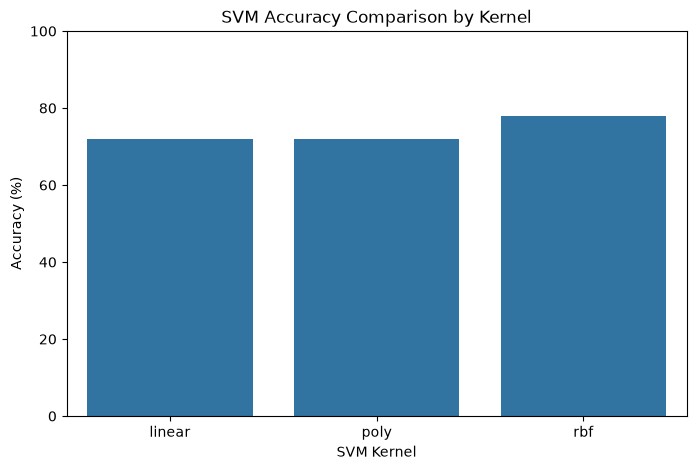

In [ ]:
# Visualize accuracy for different kernels

plt.figure(figsize=(8, 5))

sns.barplot(
    data=kernel_results_percentage,
    x="Kernel",
    y="Accuracy"
)

plt.title("SVM Accuracy Comparison by Kernel")
plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

In [ ]:
# Display the performance comparison of different SVM kernels

kernel_results_percentage

,Kernel,Accuracy,Precision,Recall,F1-Score
0,linear,72.0,76.09,67.31,71.43
1,poly,72.0,77.27,65.38,70.83
2,rbf,78.0,76.79,82.69,79.63


**Conclusion**


The dataset contain 500 records and explored to understand its structure, identify outliers, missing values, and analyze correlations between numerical variables. 

The dataset waas divided in 80% training data and 20% testing data. An SVm classifier was trained and evaluated using Accuracy, Precision, Recall adn F!_score 